In [1]:
import pandas as pd

df= pd.read_csv("diabetes_binary_classification_data.csv")
df.head


<bound method NDFrame.head of         Diabetes_binary  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0                   0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1                   0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2                   0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3                   0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4                   0.0     1.0       1.0        1.0  24.0     0.0     0.0   
...                 ...     ...       ...        ...   ...     ...     ...   
253675              0.0     1.0       1.0        1.0  45.0     0.0     0.0   
253676              1.0     1.0       1.0        1.0  18.0     0.0     0.0   
253677              0.0     0.0       0.0        1.0  28.0     0.0     0.0   
253678              0.0     1.0       0.0        1.0  23.0     0.0     0.0   
253679              1.0     1.0       1.0        1.0  25.0     0.0     0.0   

        HeartDiseaseorAttack  Phy

In [2]:
df.columns
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

(253680, 22)

In [3]:
df["Diabetes_binary"].value_counts()

# 0 = no diabetes
# 1 = prediabetes or diabetes

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

In [4]:
df["Diabetes_binary"].value_counts(normalize=True)

Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

In [5]:
numerical_features = [
    "BMI",
    "MentHlth",
    "PhysHlth"
]

ordinal_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income"
]

binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

print("Numerical:", len(numerical_features))
print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))
print("Total features:", len(numerical_features) + len(ordinal_features) + len(binary_features))

Numerical: 3
Ordinal: 4
Binary: 14
Total features: 21


In [6]:
#- BMI is a numerical feature. A value such as 30 means the respondent has a BMI of 30.
#- HighBP is a binary categorical feature. 0 means no high blood pressure and 1 means yes.
#- Age is an ordinal categorical feature. The numbers represent ordered age groups, not actual age in years.

In [7]:
df.groupby("Diabetes_binary")["BMI"].describe()

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,218334.0,27.805770,6.291414,12.0,24.0,27.0,31.0,98.0
1.0,35346.0,31.944011,7.363401,13.0,27.0,31.0,35.0,98.0


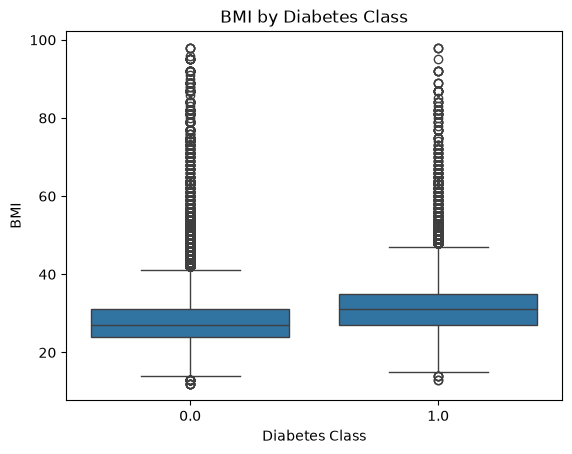

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI"
)

plt.title("BMI by Diabetes Class")
plt.xlabel("Diabetes Class")
plt.ylabel("BMI")
plt.show()

In [9]:
pd.crosstab(
    df["HighBP"],
    df["Diabetes_binary"],
    normalize="index"
)

Diabetes_binary,0.0,1.0
HighBP,,
0.0,0.939648,0.060352
1.0,0.755543,0.244457


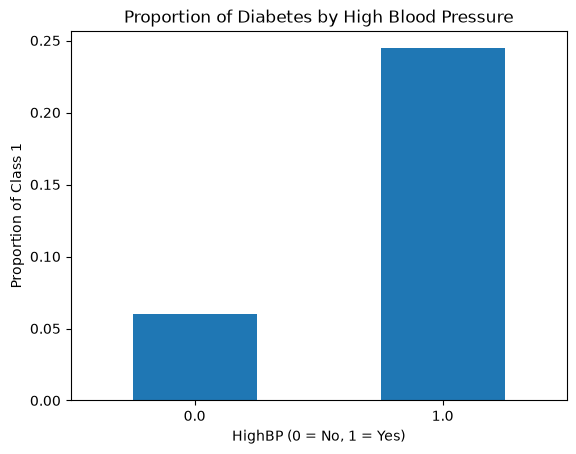

In [10]:
highbp_diabetes = df.groupby("HighBP")["Diabetes_binary"].mean()

highbp_diabetes.plot(kind="bar")

plt.title("Proportion of Diabetes by High Blood Pressure")
plt.xlabel("HighBP (0 = No, 1 = Yes)")
plt.ylabel("Proportion of Class 1")
plt.xticks(rotation=0)
plt.show()

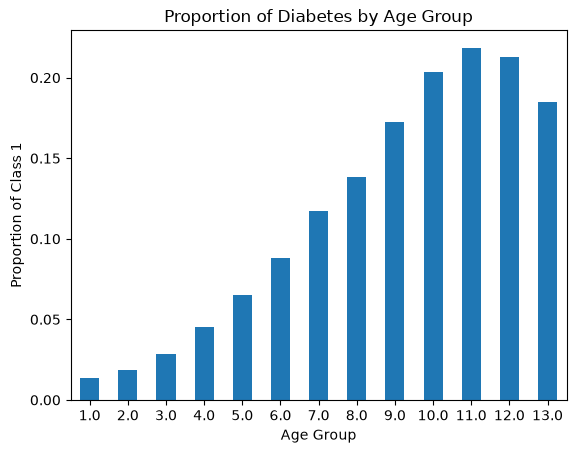

In [11]:
### Age
age_diabetes = df.groupby("Age")["Diabetes_binary"].mean()

age_diabetes.plot(kind="bar")
plt.title("Proportion of Diabetes by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Proportion of Class 1")
plt.xticks(rotation=0)
plt.show()


MentHlth
                    count      mean       std  min  25%  50%  75%   max
Diabetes_binary                                                        
0.0              218334.0  2.978034  7.111865  0.0  0.0  0.0  2.0  30.0
1.0               35346.0  4.461806  8.947717  0.0  0.0  0.0  3.0  30.0


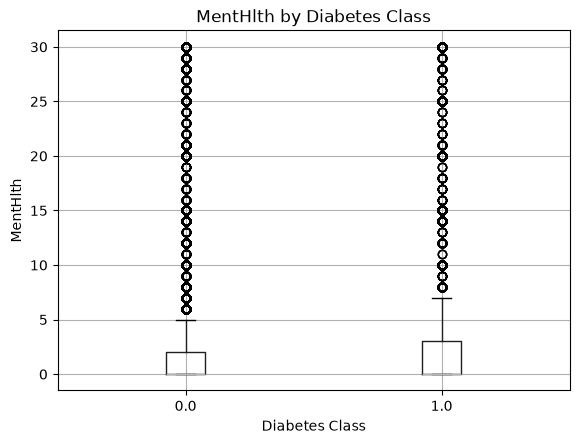


PhysHlth
                    count      mean        std  min  25%  50%   75%   max
Diabetes_binary                                                          
0.0              218334.0  3.641082   8.064600  0.0  0.0  0.0   2.0  30.0
1.0               35346.0  7.954479  11.301491  0.0  0.0  1.0  15.0  30.0


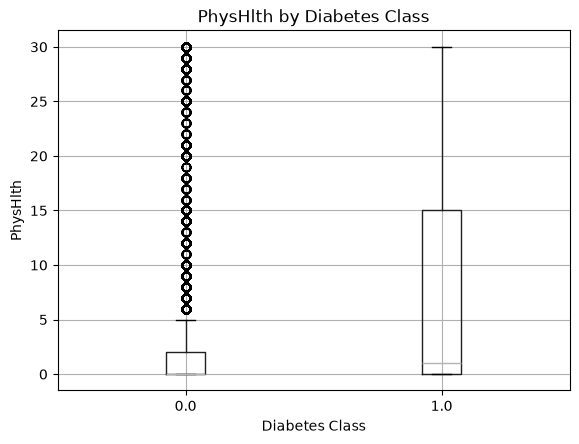

In [12]:
for feature in ["MentHlth", "PhysHlth"]:

    print(f"\n{feature}")
    print(df.groupby("Diabetes_binary")[feature].describe())

    df.boxplot(
        column=feature,
        by="Diabetes_binary"
    )

    plt.title(f"{feature} by Diabetes Class")
    plt.suptitle("")
    plt.xlabel("Diabetes Class")
    plt.ylabel(feature)
    plt.show()


HighChol
HighChol
0.0    0.079814
1.0    0.220149
Name: Diabetes_binary, dtype: float64


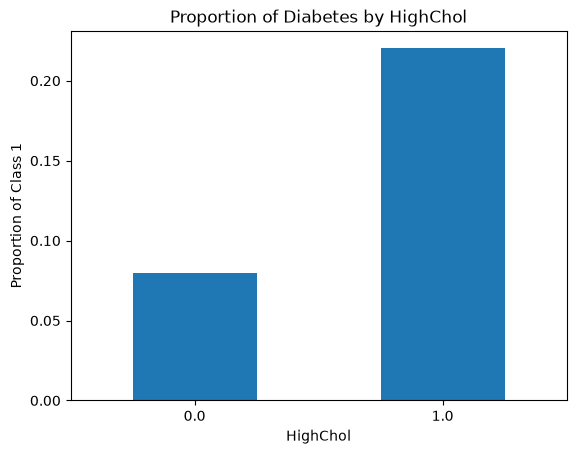


CholCheck
CholCheck
0.0    0.025449
1.0    0.143749
Name: Diabetes_binary, dtype: float64


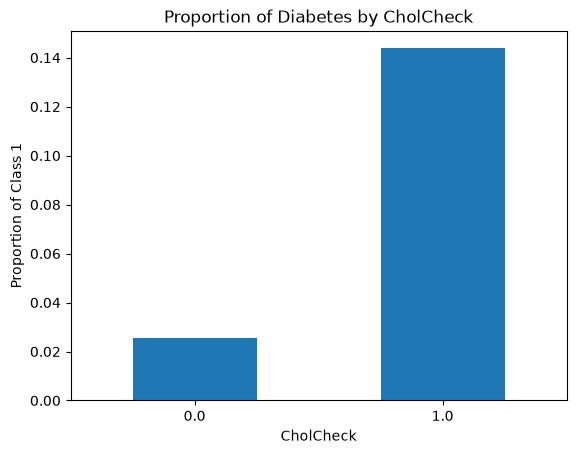


Smoker
Smoker
0.0    0.120553
1.0    0.162929
Name: Diabetes_binary, dtype: float64


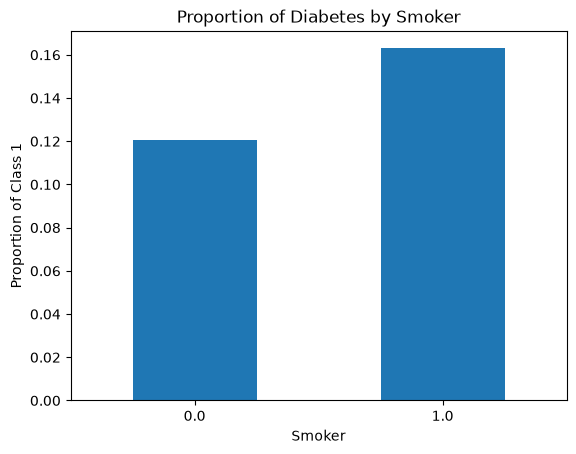


Stroke
Stroke
0.0    0.131798
1.0    0.317528
Name: Diabetes_binary, dtype: float64


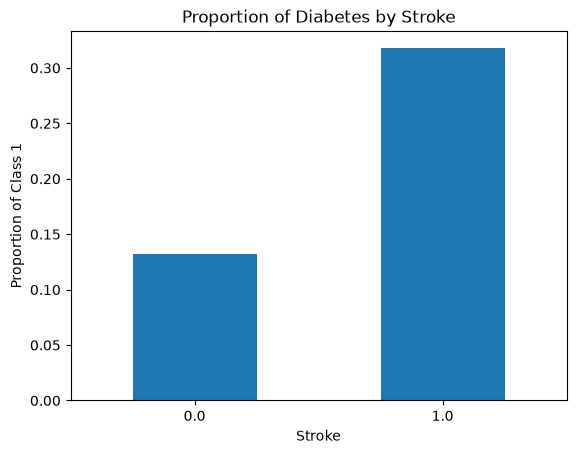


HeartDiseaseorAttack
HeartDiseaseorAttack
0.0    0.119537
1.0    0.329720
Name: Diabetes_binary, dtype: float64


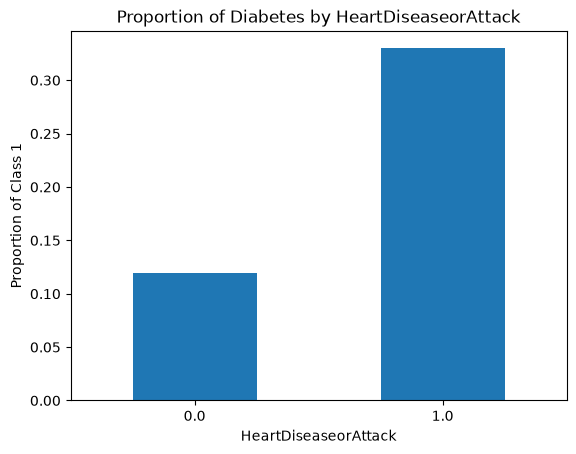


PhysActivity
PhysActivity
0.0    0.211448
1.0    0.116127
Name: Diabetes_binary, dtype: float64


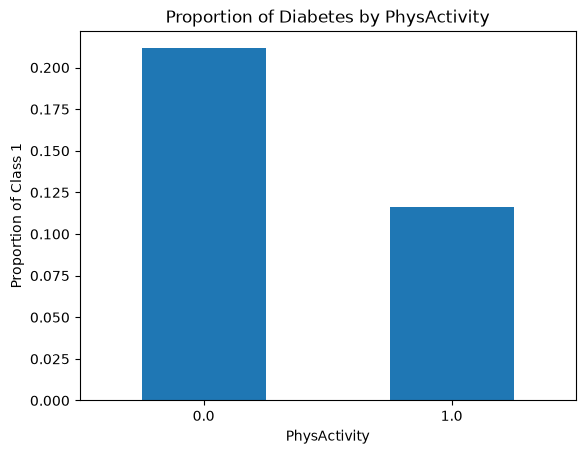


Fruits
Fruits
0.0    0.157929
1.0    0.128609
Name: Diabetes_binary, dtype: float64


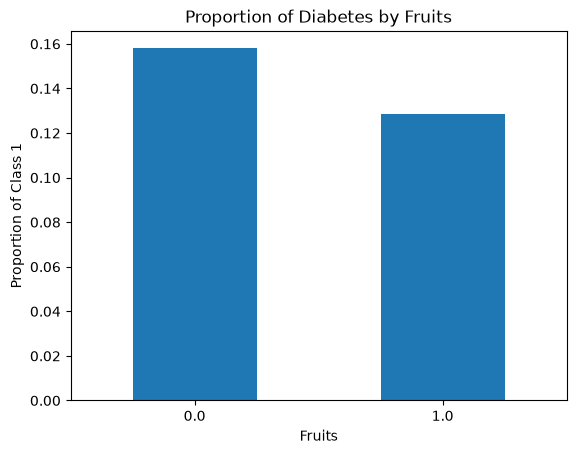


Veggies
Veggies
0.0    0.179979
1.0    0.129887
Name: Diabetes_binary, dtype: float64


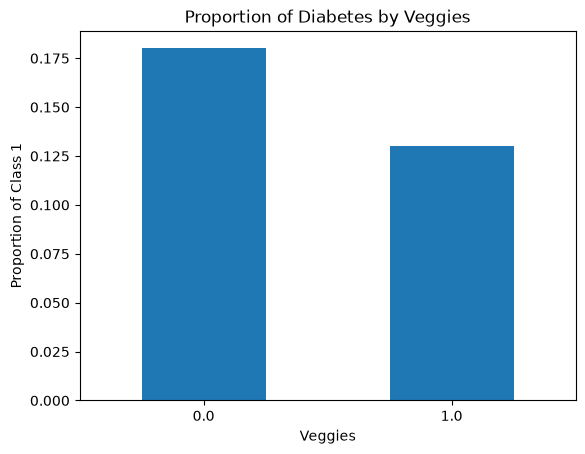


HvyAlcoholConsump
HvyAlcoholConsump
0.0    0.144154
1.0    0.058361
Name: Diabetes_binary, dtype: float64


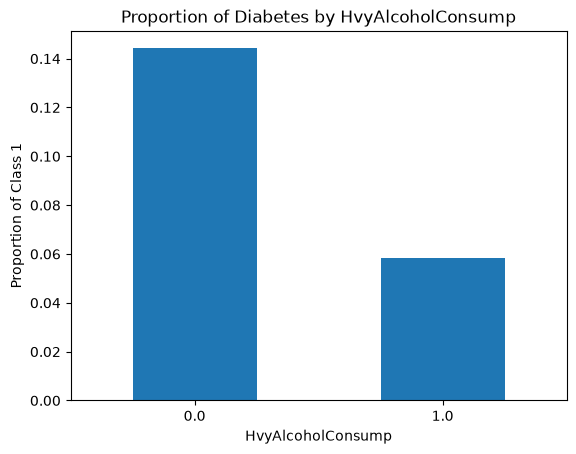


AnyHealthcare
AnyHealthcare
0.0    0.11452
1.0    0.14061
Name: Diabetes_binary, dtype: float64


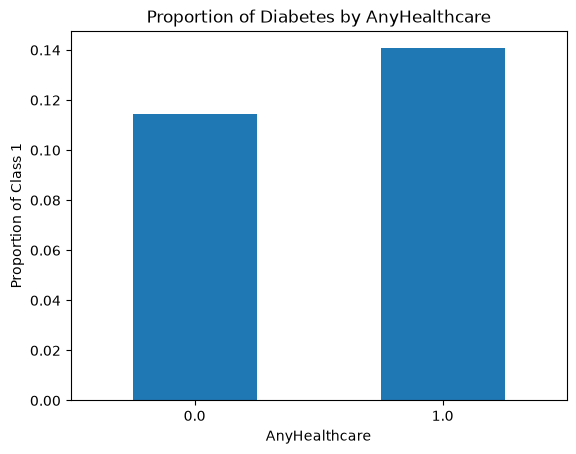


NoDocbcCost
NoDocbcCost
0.0    0.136033
1.0    0.175236
Name: Diabetes_binary, dtype: float64


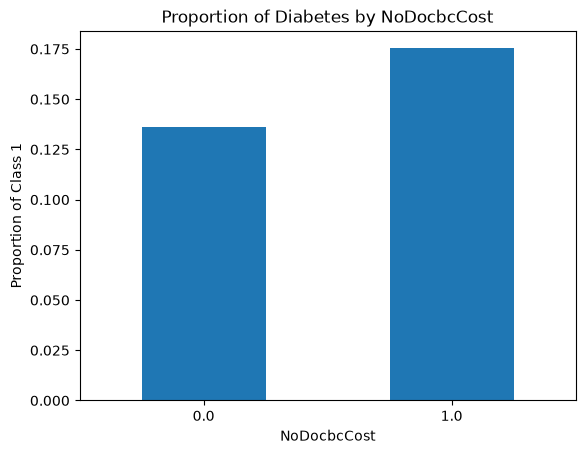


DiffWalk
DiffWalk
0.0    0.105329
1.0    0.307463
Name: Diabetes_binary, dtype: float64


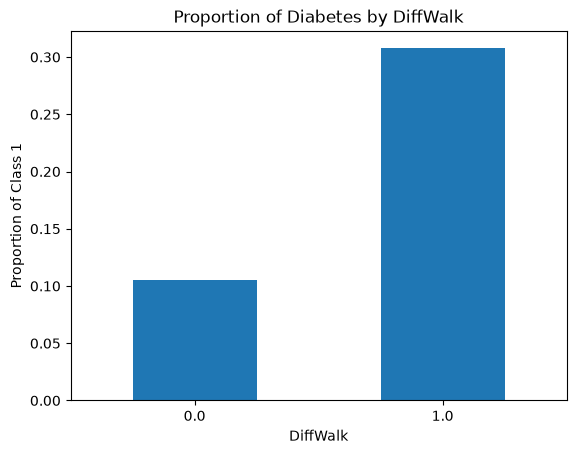


Sex
Sex
0.0    0.129679
1.0    0.151603
Name: Diabetes_binary, dtype: float64


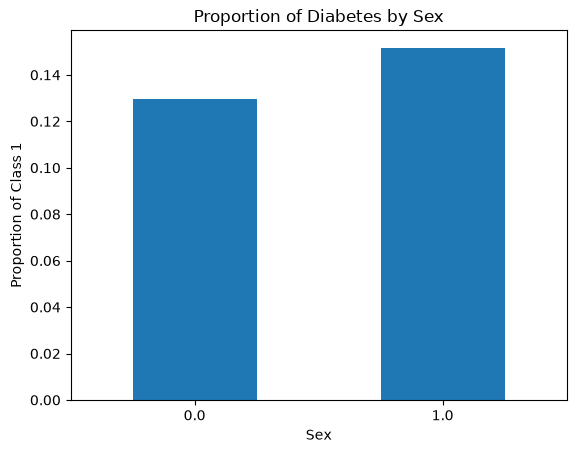

In [13]:
### Remaining Binary Features

for feature in binary_features:

    if feature == "HighBP":
        continue

    proportion = df.groupby(feature)["Diabetes_binary"].mean()

    print(f"\n{feature}")
    print(proportion)

    proportion.plot(kind="bar")

    plt.title(f"Proportion of Diabetes by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Proportion of Class 1")
    plt.xticks(rotation=0)
    plt.show()


GenHlth
GenHlth
1.0    0.025166
2.0    0.071629
3.0    0.177894
4.0    0.310105
5.0    0.378942
Name: Diabetes_binary, dtype: float64


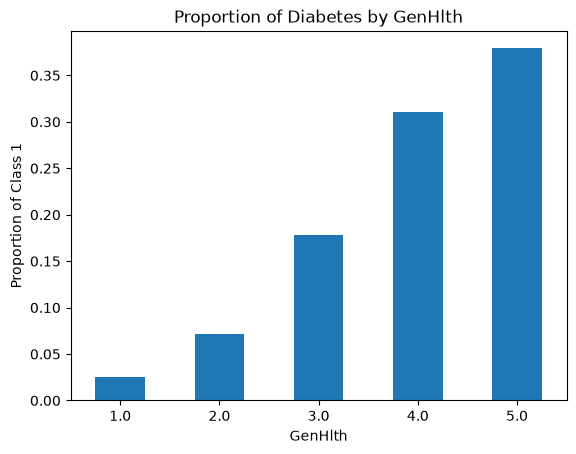


Education
Education
1.0    0.270115
2.0    0.292605
3.0    0.242245
4.0    0.176351
5.0    0.148105
6.0    0.096902
Name: Diabetes_binary, dtype: float64


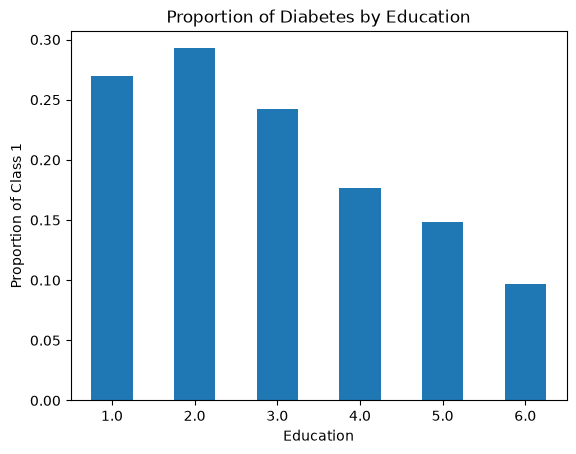


Income
Income
1.0    0.242891
2.0    0.261903
3.0    0.223084
4.0    0.201341
5.0    0.174014
6.0    0.145078
7.0    0.121821
8.0    0.079604
Name: Diabetes_binary, dtype: float64


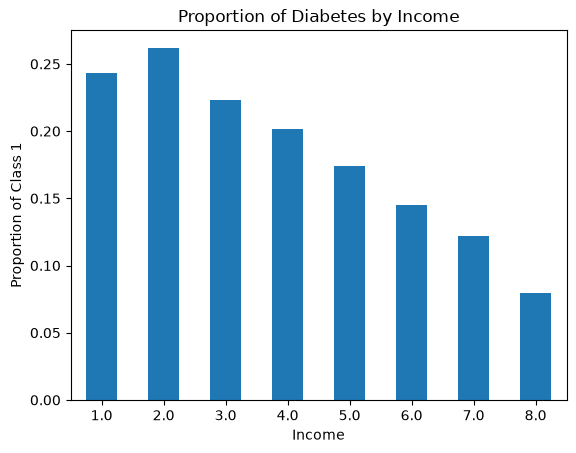

In [14]:
### Remaining Ordinal Features
for feature in ["GenHlth", "Education", "Income"]:

    proportion = df.groupby(feature)["Diabetes_binary"].mean()

    print(f"\n{feature}")
    print(proportion)

    proportion.plot(kind="bar")

    plt.title(f"Proportion of Diabetes by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Proportion of Class 1")
    plt.xticks(rotation=0)
    plt.show()

In [15]:
## Step 5 - Create Features and Target
X = df.drop(columns="Diabetes_binary")
y = df["Diabetes_binary"]

In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (253680, 21)
y shape: (253680,)


In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline

ordinal_categories = [
    [1, 2, 3, 4, 5],                         # GenHlth
    list(range(1, 14)),                       # Age
    [1, 2, 3, 4, 5, 6],                      # Education
    [1, 2, 3, 4, 5, 6, 7, 8]                # Income
]

ordinal_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income"
]




In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "ordinal",
            OrdinalEncoder(categories=ordinal_categories),
            ordinal_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]
)

In [20]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['HighBP','HighChol','CholCheck',...,'Age','Education','Income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrou

In [21]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted classes:")
print(y_pred[:10])

print("\nPredicted probabilities:")
print(y_prob[:10])

Predicted classes:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted probabilities:
[0.15419819 0.29174308 0.01994643 0.03319724 0.48115288 0.11880652
 0.028723   0.01087112 0.05288479 0.16686996]


In [22]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Confusion Matrix:
[[42616  1051]
 [ 5947  1122]]

Accuracy: 0.8620703248186692
Precision: 0.5163368614818223
Recall: 0.15872117696986843
F1 Score: 0.24280458775156893


In [24]:
y_pred_050 = (y_prob >= 0.50).astype(int)

print("model.predict():")
print(y_pred[:10])

print("\nUsing probability >= 0.50:")
print(y_pred_050[:10])

print("\nAre all predictions identical?")
print((y_pred == y_pred_050).all())

model.predict():
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Using probability >= 0.50:
[0 0 0 0 0 0 0 0 0 0]

Are all predictions identical?
True


In [25]:
y_pred_040 = (y_prob >= 0.40).astype(int)

def evaluate_threshold(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "False Positives": fp,
        "False Negatives": fn
    }

results_050 = evaluate_threshold(y_test, y_pred_050)
results_040 = evaluate_threshold(y_test, y_pred_040)

threshold_results = pd.DataFrame(
    [results_050, results_040],
    index=["0.50", "0.40"]
)

threshold_results

,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0.50,0.862070,0.516337,0.158721,0.242805,1051,5947
0.40,0.856394,0.473097,0.269911,0.343722,2125,5161


In [26]:
print("Confusion Matrix - Threshold 0.50")
print(confusion_matrix(y_test, y_pred_050))

print("\nConfusion Matrix - Threshold 0.40")
print(confusion_matrix(y_test, y_pred_040))

Confusion Matrix - Threshold 0.50
[[42616  1051]
 [ 5947  1122]]

Confusion Matrix - Threshold 0.40
[[41542  2125]
 [ 5161  1908]]


In [28]:
### Threshold Interpretation

#Lowering the decision threshold from 0.50 to 0.40 increased the number of observations predicted as class 1.

#Recall increased from about 15.9% to 27.0%, and false negatives decreased from 5,947 to 5,161. This means the lower threshold detected more of the actual class-1 observations.

#However, false positives increased from 1,051 to 2,125, and precision decreased from about 51.6% to 47.3%.

#The Logistic Regression model itself was not retrained. Only the rule used to convert predicted probabilities into class labels was changed.